<a href="https://colab.research.google.com/github/JosBae/510FinalProj/blob/main/510FinalProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os
os.chdir("/content/drive/MyDrive/Colab Notebooks/Final Project")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#reading survey data checking what columns exist
surveydata = pd.read_csv('2026aisurvey.csv', encoding='cp1252')
surveydata.columns

Index(['Id', 'Date', 'Are you studying part time* or full time?',
       'Years of study', 'Major/Program of Study',
       'Have you explored generative AI on your own?',
       'How often do you use generative AI? (daily, weekly, monthly, experimental)',
       'List three AI-powered tools you most often use. If you don't use AI powered tools, answer NONE.',
       'List three of your most common uses of generative AI. If you don't use generative AI, answer NONE.',
       'Have you used generative AI in completing your coursework?',
       'If so, how have you used it?',
       'Has a professor/course instructor taught you how to use any generative AI tools?',
       'Do you have a clear understanding of your professors' attitudes towards the use of AI-powered tools in your classes?',
       'What is your attitude towards the use of generative AI in your program of study? (Select top 3)',
       'Please rate how much you agree with the following statements .Grammarly helps me work mo

In [ ]:
#renaming columns of survey data in a copy to avoid excessively long column names

surveydf = surveydata
surveydf.columns = surveydf.columns.str.replace("\xa0", " ", regex=False)
col_names = {'Id': 'id',
             'Date': 'date',
             'Are you studying part time* or full time?': 'full_time',
             'Years of study': 'year',
             'Major/Program of Study': 'major',
             'Have you explored generative AI on your own?': 'ai_use',
             'How often do you use generative AI? (daily, weekly, monthly, experimental)': 'ai_freq',
             "List three AI-powered tools you most often use. If you don't use AI powered tools, answer NONE.": 'ai_top_tools',
             "List three of your most common uses of generative AI. If you don't use generative AI, answer NONE.": 'ai_top_uses',
             'Have you used generative AI in completing your coursework?': 'ai_school_use',
             'If so, how have you used it?': 'ai_school_use_dtl',
             'Has a professor/course instructor taught you how to use any generative AI tools?': 'prof_educ',
             "Do you have a clear understanding of your professors' attitudes towards the use of AI-powered tools in your classes?": 'prof_att',
             'What is your attitude towards the use of generative AI in your program of study? (Select top 3)': 'stud_att',
             'Please rate how much you agree with the following statements .Grammarly helps me work more efficiently': 'gram_eff',
             'Please rate how much you agree with the following statements .Grammarly helps me reduce errors in my writing': 'gram_err',
             'Please rate how much you agree with the following statements .Grammarly helps me communicate more clearly': 'gram_comm',
             'Please rate how much you agree with the following statements .Grammarly helps me feel more confident in my communication': 'gram_conf',
             'Please rate how much you agree with the following statements .I feel confident about my writing when when I use Grammarly Authorship Report': 'gram_rep_conf',
             'Do your professors/course instructors have an explicit course policy outlined in course syllabi about the authorized or unauthorized use of AI-powered tools?': 'prof_pol',
             'If your professors/course instructors have an explicit course policy on the use of generative AI, is the policy clear and easy to understand?': 'prof_pol_ez',
             'Are you aware of any departmental policy on the use of generative AI as part of your program of study?': 'dep_pol',
             'Have you had experiences in Fall 2025 or Spring 2026 where you were accused of unauthorized use of AI-powered tools to complete assignments?': 'ai_accuse',
             'If you have had experiences of alleged unauthorized student use of AI-powered tools, how did you handle it?': 'ai_accuse_exp',
             'Have your professors/course instructors banned the use of generative AI in completing coursework?': 'ai_prof_ban',
             'Do your professors/course instructors use any AI-detection tools in your courses?': 'ai_detect',
             'If your professors/course instructors have used AI-detection tools, how did that impact your use of AI?': 'ai_detect_effect',
             'What has been the greatest challenge with learning about AI in college?': 'ai_educ_challenge',
             'Do you believe that AI should be adopted into college curricula in order to prepare students for future careers?': 'ai_adopt_att',
             'Have you completed any generative AI training to help you understand how to use it?': 'ai_train',
             'If you have completed generative AI training to help you understand and use AI, what kinds of training have you completed? (Check all that apply.)': 'ai_train_dtl',
             'Which AI trainings/resources were most helpful?': 'ai_train_top',
             "Please use this space to add anything else related to teaching and learning with/about generative AI that hasn't been asked on this survey.": 'comments'}

surveydf = surveydata.rename(columns=col_names)

In [ ]:
surveydf.head()

,id,date,full_time,year,major,ai_use,ai_freq,ai_top_tools,ai_top_uses,ai_school_use,...,ai_accuse_exp,ai_prof_ban,ai_detect,ai_detect_effect,ai_educ_challenge,ai_adopt_att,ai_train,ai_train_dtl,ai_train_top,comments
0,1,3/30/2026,full time,4th year,International studies,Yes,Daily,"CHAT GPT, Google gemini, notebook lm","translation, summarize reading assignment, che...",Yes,...,i explained that since i am not a native engli...,Yes,Unsure,NaN,I worry that I won't be prepared for the future.;,Yes,No,NaN,NaN,NaN
1,2,3/30/2026,full time,3rd year,Physics and Mathematics,No,NaN,NaN,NaN,No,...,NaN,Yes,Unsure,NaN,I worry that I won't be prepared for the futur...,Yes,No,NaN,NaN,One of my most recent classes spoke about AI b...
2,3,3/30/2026,full time,4th year,"Marketing/ Bachelors of Science, Dance/ Bachel...",Yes,Daily,"ChatGPT, Google Gemini, Grammarly",I use AI as a search engine for general questi...,Yes,...,NaN,Yes,Yes,I will only use AI for specific purposes like ...,The professor/instructor doesn't know enough a...,Yes,Yes,Coursera course on AI;Linkedin Learning course...,"Any is good, but nothing is better then a teac...",NaN
3,4,3/31/2026,part time,1st year,"Communications, Environmental and sustainabili...",Yes,Never,NONE,NONE,No,...,NaN,Yes,Unsure,NaN,"My instructor wants me to use generative AI, b...",No,No,NaN,NaN,Rather than AI be adopted into every course cu...
4,5,3/31/2026,full time,3rd year,English and Jewish Studies,Yes,Never,NONE,NONE,No,...,I had to pull up every single document I worke...,Yes,Unsure,NaN,I would rather not use it because I'm concerne...,No,No,NaN,NaN,Please stop using it. It's so bad for the envi...


In [ ]:
#sanitizing weird space characters
surveydf['stud_att'] = surveydf.stud_att.str.replace("\xa0", " ", regex=False)

In [ ]:
surveydf.columns

Index(['id', 'date', 'full_time', 'year', 'major', 'ai_use', 'ai_freq',
       'ai_top_tools', 'ai_top_uses', 'ai_school_use', 'ai_school_use_dtl',
       'prof_educ', 'prof_att', 'stud_att', 'gram_eff', 'gram_err',
       'gram_comm', 'gram_conf', 'gram_rep_conf', 'prof_pol', 'prof_pol_ez',
       'dep_pol', 'ai_accuse', 'ai_accuse_exp', 'ai_prof_ban', 'ai_detect',
       'ai_detect_effect', 'ai_educ_challenge', 'ai_adopt_att', 'ai_train',
       'ai_train_dtl', 'ai_train_top', 'comments'],
      dtype='object')

In [ ]:
#creating function to make using describe/value_counts faster
def descr(data, column):
  print(data[column].describe())
  print(data[column].value_counts())

In [ ]:
descr(surveydf, 'year')

count          316
unique          10
top       1st year
freq           148
Name: year, dtype: object
year
1st year            148
3rd year             57
4th year             56
2nd year             40
5th year              4
6th year              4
Graduate Student      3
Audit                 2
Doctorate             1
Retired student       1
Name: count, dtype: int64


In [ ]:
#using describe function
descr(surveydf, 'major')

count            316
unique           162
top       Psychology
freq              17
Name: major, dtype: object
major
Psychology                              17
Biology                                 15
Business Administration                 12
Marketing                               12
Political Science                       11
                                        ..
Finance, Project Management              1
Finance, Data Science                    1
Health services admin and management     1
Meteorology                              1
M.S. Data Science & Analytics            1
Name: count, Length: 162, dtype: int64


In [ ]:
#checking how many Computer Science majors answered the survey

surveydf.where(surveydf.major == 'Computer Science').count()

,0
id,3
date,3
full_time,3
year,3
major,3
ai_use,3
ai_freq,3
ai_top_tools,3
ai_top_uses,3
ai_school_use,3


In [ ]:
#listing unique responses in student attitude multiple choice answers
stud_att_resp_list = []
for answer in surveydf['stud_att'].dropna().unique():
  answer_list = answer.split(';')
  for response in answer_list:
    response = response.strip()
    if response not in stud_att_resp_list:
      stud_att_resp_list.append(response)

stud_att_resp_list

['AI is beneficial for developing ideas, language, and structure for my coursework.',
 'AI helps me work through and gain a better understanding of my course topics.',
 '',
 'AI presents challenges to honesty and academic integrity in education.',
 'AI is important for me to learn because of my field of study.',
 'AI creates ethical concerns about perpetuating biases.',
 'I want my program to incorporate AI tools into its curriculum.',
 "I don't want to use AI in my courses at all.",
 "I don't know enough about it yet."]

In [ ]:
#creating attitudes df out of attitude related columns in main df

att_cols = ['id', 'year','major','stud_att','ai_adopt_att']
attitudes = surveydf[att_cols]

In [ ]:
#function using np.select to create a new column within a dataframe depending on conditions/choices given by user

def cat_var_quantize(df, newcol, condlist, choicelist):
  df[newcol] = np.select(condlist, choicelist)

In [ ]:
#using categorical variable quantizer function to quantize AI adoption attitude answers

att_condlist = [attitudes.ai_adopt_att=='No', attitudes.ai_adopt_att=='Undecided', attitudes.ai_adopt_att=='Yes']
att_choicelist = [-1, 0, 1]

cat_var_quantize(attitudes, 'ai_adopt_int', att_condlist, att_choicelist)
attitudes['ai_adopt_int'].describe()

/tmp/ipykernel_781/3239524795.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[newcol] = np.select(condlist, choicelist)


,ai_adopt_int
count,316.000000
mean,-0.031646
std,0.861309
min,-1.000000
25%,-1.000000
50%,0.000000
75%,1.000000
max,1.000000


In [ ]:
#splitting responses into positive- and negative-coded responses
pos_resp = ['AI is beneficial for developing ideas, language, and structure for my coursework.',
 'AI helps me work through and gain a better understanding of my course topics.',
 'AI is important for me to learn because of my field of study.',
 'I want my program to incorporate AI tools into its curriculum.']

neg_resp = ['AI presents challenges to honesty and academic integrity in education.',
 'AI creates ethical concerns about perpetuating biases.',
 "I don't want to use AI in my courses at all."]

#creating net response value column based on overall sentiment (weighing all responses equally seems problematic but weights can be adjusted later)
def answer_score(answer):
  if pd.isna(answer):
        return np.nan

  net_sent = 0
  for response in answer.split(';'):
    response = response.strip()
    if response in pos_resp:
      net_sent+=1
    elif response in neg_resp:
      net_sent-=1
  return net_sent





In [ ]:
attitudes['resp_net'] = attitudes['stud_att'].apply(answer_score)
attitudes['resp_net'].describe()

/tmp/ipykernel_781/2986760022.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  attitudes['resp_net'] = attitudes['stud_att'].apply(answer_score)


,resp_net
count,313.000000
mean,-0.335463
std,2.107508
min,-3.000000
25%,-3.000000
50%,0.000000
75%,1.000000
max,3.000000


In [ ]:
#basic check for how many times an attitude option was selected in whole survey
for option in stud_att_resp_list:
  option_count = 0
  for answer in attitudes['stud_att'].dropna():
    for response in answer.split(';'):
      response = response.strip()
      if response == option:
        option_count += 1
  print(f'"{option}" appeared {option_count} times.')



"AI is beneficial for developing ideas, language, and structure for my coursework." appeared 128 times.
"AI helps me work through and gain a better understanding of my course topics." appeared 140 times.
"" appeared 228 times.
"AI presents challenges to honesty and academic integrity in education." appeared 182 times.
"AI is important for me to learn because of my field of study." appeared 43 times.
"AI creates ethical concerns about perpetuating biases." appeared 157 times.
"I want my program to incorporate AI tools into its curriculum." appeared 39 times.
"I don't want to use AI in my courses at all." appeared 116 times.
"I don't know enough about it yet." appeared 20 times.


<Axes: ylabel='Frequency'>

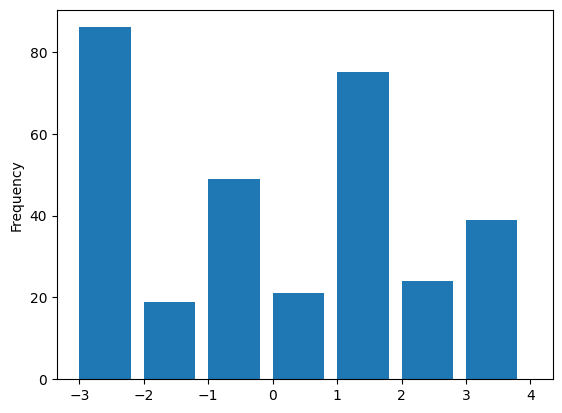

In [ ]:
#distribution of net response sentiment from student multiple choice selection

fig, axes = plt.subplots(1, 1)
data = attitudes['resp_net']
bins = np.arange(min(data), max(data) + 2)
data.plot.hist(bins=bins, width=0.8)

<Axes: xlabel='ai_adopt_att'>

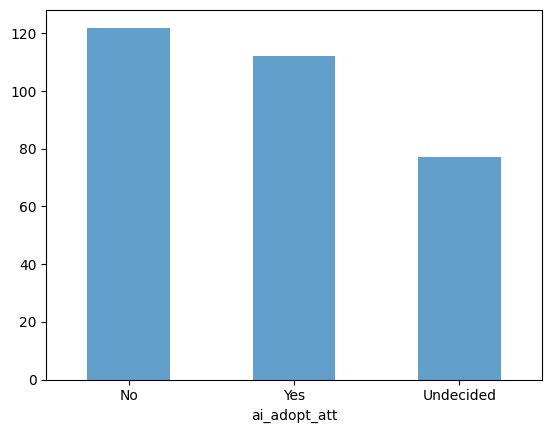

In [ ]:
#distribution of answers regarding whether AI should be adopted into schools.

fig, axes = plt.subplots(1, 1)
data = attitudes['ai_adopt_att'].value_counts()
data.plot.bar(ax=axes, alpha=0.7, rot = 0)

In [ ]:
plt.close()

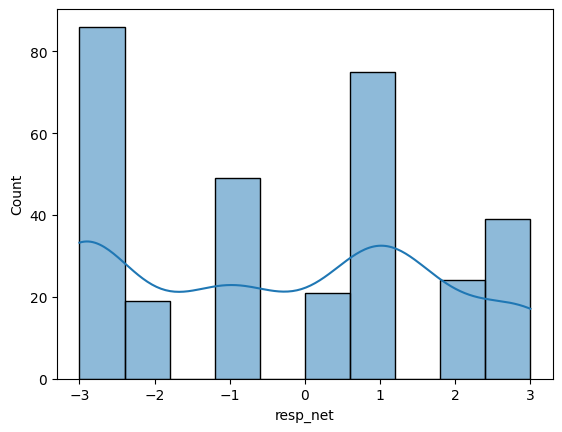

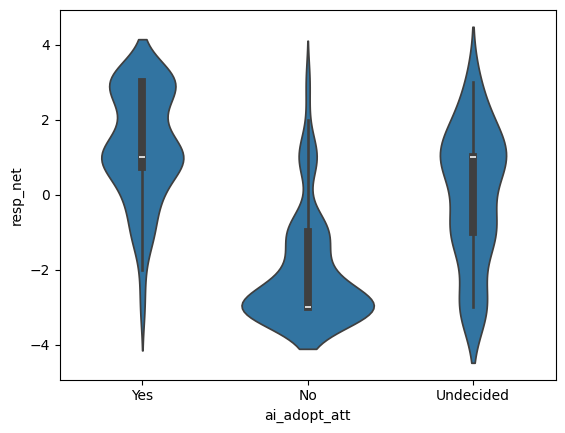

In [ ]:
# histogram and violin plot for overall response and adoption of ai into school
import seaborn as sns

plt.figure
sns.histplot(attitudes, x='resp_net', kde=True)
plt.show()

plt.figure
sns.violinplot(attitudes, x='ai_adopt_att', y='resp_net')
plt.show()